# Objectives à la carte — one T-maze, five objectives, one term tree

**What this is.** One `System` — a T-maze, declared once — planned five times against five
different objectives. The model does not change between the columns: same tensors, same
transition, same likelihood, same beliefs. What changes is the *objective declaration*, one
line each. What comes back each time is a **term tree** — `term -> block -> Interval`, per
policy — carrying every term's registered sign in G and every leaf's `derived` flag, which
says whether the number is a derivation or an estimate.

| # | objective | the line that differs |
|---|---|---|
| 1 | by the book — expected free energy | `obs_targets={"reward": …}`, `epistemic=True` |
| 2 | pure curiosity | `epistemic=("*",)`, no targets |
| 3 | maximum occupancy (MOP) | `terms=("occupancy:transition:location",)` |
| 4 | Dirichlet novelty | a learnable `B`, `epistemic=("transition:*",)` |
| 5 | the certainty tax | `state_targets=` vs `obs_targets=` on one channel |

Rows 1, 2 and 4 are the `epistemic` selector (`per-variable-infogain.md`); row 3 is the
`terms=` selector (`amortization.md` A12); row 5 is a designation, not a selector. Where each
term sits — which declared conditional it reads, which functional it computes, which sign it
takes — is `docs/design/objective-terms.md`.

In [1]:
import dataclasses

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from hybrid_aif import Categorical, ConditionalCategorical
from hybrid_aif.distributions import ConditionalDirichlet
from hybrid_aif.objectives.base import term_sign, total
from hybrid_aif.reference.envs.tmaze import CENTRE, MIDDLE, tmaze
from hybrid_aif.system import System, SystemParams

# One palette for the notebook; same hue always means the same thing.
TEAL = "#00897B"  # the objective under discussion
AMBER = "#B8860B"  # its comparison
GREY = "#ADADAD"
INK = "#3A3A3A"
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "font.size": 10,
        "axes.titlesize": 11.5,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.edgecolor": "#CCCCCC",
        "axes.labelcolor": INK,
        "text.color": INK,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

LOC = ("centre", "left arm", "right arm", "cue", "middle")
SEED = 1  # one seed for every column: the differences below are the objective, not the draw

## The world: a slippery T-maze

The classic five-location T-maze from `hybrid_aif.reference.envs.tmaze` (pymdp's `TMaze`) — centre, two arms, a
cue location, and the middle junction — with one change: **a move fails with probability 0.2**
and leaves the agent where it was. One arm rewards and the other punishes; which is which is
the `context` factor, fixed per episode and invisible except from the cue.

The slip is not decoration. A deterministic maze has `H(s' | s, a) = 0` for every state and
action, so column 3's occupancy leaf would be identically zero and there would be nothing to
show. It also gives the location channel something to predict, which is why an `infogain`
leaf appears there in column 2.

In [2]:
def _cc(table, parent_ndims):
    return ConditionalCategorical(
        log_table=jnp.log(jnp.clip(table, 1e-16)), parent_ndims=parent_ndims
    )


def slippery_tmaze(policy_len=3, slip=0.2, **objective):
    # The declared T-maze; `objective` is whatever the column under discussion changes.
    env, p = tmaze(reward_probability=0.98, punishment_probability=0.98, cue_validity=0.98)
    stay = jnp.eye(5)[:, :, None] * jnp.ones((1, 1, 5))
    B_loc = (1 - slip) * jnp.asarray(p.transition[0]) + slip * stay
    system = System(
        A_deps=env.A_deps,
        B_deps=env.B_deps,
        controlled=(True, False),
        policy_len=policy_len,
        gamma=16.0,
        modality_names=("location_obs", "reward", "cue"),
        factor_names=("location", "context"),
        **objective,
    )
    params = SystemParams(  # the pymdp-shaped tables, keyed by name
        likelihood={
            m: _cc(a, len(d))
            for m, a, d in zip(system.names.modalities, p.likelihood, env.A_deps, strict=True)
        },
        transition={"location": _cc(B_loc, 2), "context": _cc(jnp.asarray(p.transition[1]), 2)},
        initial_state_prior={
            f: Categorical.from_probs(d)
            for f, d in zip(system.names.states, p.initial_state_prior, strict=True)
        },
        obs_targets={"reward": Categorical(logits=jnp.asarray([0.0, 4.0, -6.0]))},
        state_targets={},
        terminal_targets={},
    )
    return system, params


BASE, BASE_PARAMS = slippery_tmaze()

### Two helpers

`episode` is the canonical loop from `System.learn`'s docstring — perceive, (learn), act,
push the prior forward — run against the declared model itself as the environment
(`System.as_env`: the same tensors run forward). `term_table` prints the term tree of the
policy the objective actually chose: term, block, the term's registered sign in G, the leaf,
and whether the leaf is exact.

In [3]:
def episode(system, params, key, steps=10, context=0, learning=False):
    # Perceive, (learn), act, push the prior forward. Returns the trace, the rewards
    # collected, and the first tick's (term tree, policy posterior).
    env, env_params = system.as_env(params)
    start = {"location": jnp.asarray(CENTRE), "context": jnp.asarray(context)}
    obs, state = env.reset(key, env_params, state=start)
    priors = prev_beliefs = prev_action = first = None
    visited, rewarded = [int(obs["location_obs"])], 0
    for _ in range(steps):
        beliefs, _ = system.infer_states(params, obs, priors)
        if learning and prev_beliefs is not None:
            params = system.learn(params, obs, beliefs, prev_beliefs, prev_action)
        key, k_act, k_env = jax.random.split(key, 3)
        action, q_pi, tree = system.act(k_act, params, beliefs)
        first = first or (tree, q_pi)
        priors = system.update_empirical_prior(params, beliefs, action)
        prev_beliefs, prev_action = beliefs, action
        obs, state = env.step(k_env, state, action, env_params)
        visited.append(int(obs["location_obs"]))
        rewarded += int(obs["reward"] == 1)
    return visited, rewarded, first


def term_table(system, params, tree, q_pi):
    # The term tree of the policy this objective chose, leaf by leaf.
    k = int(jnp.argmax(q_pi.probs))
    plan = " → ".join(LOC[a] for a in np.asarray(system.policies(params))[k][:, 0])
    g = total(tree)
    print(f"chosen plan:  {plan}")
    print(f"G = {float(g.midpoint[k]):+7.3f}   ({'exact' if g.derived else 'not a bound'})\n")
    print(f"  {'term':<14}{'block':<22}{'sign':>5}{'leaf':>10}   warrant")
    for term, blocks in sorted(tree.items()):
        for block, leaf in sorted(blocks.items()):
            print(
                f"  {term:<14}{block:<22}{term_sign(term):>+5.0f}"
                f"{float(leaf.midpoint[k]):>10.3f}   {'exact' if leaf.derived else 'estimate'}"
            )


def summarise(name, visited, rewarded):
    counts = np.bincount(np.asarray(visited), minlength=5)
    where = "  ".join(f"{LOC[i]} {c}" for i, c in enumerate(counts) if c)
    print(f"{name}: {where}   |   rewards collected: {rewarded}")
    return counts


visits, rewards = {}, {}

## 1. By the book — the classic EFE agent

Preferences over the reward channel, and the `epistemic` term on. `G = risk + ambiguity`,
or equivalently `−(utility + info gain)` — this System uses the second decomposition, so the
tree carries `utility` (the reward channel's cross-entropy against the target) and `infogain`
(one leaf per observation channel, keyed by the *observing channel*, V3).

In [4]:
system, params = slippery_tmaze(epistemic=True)  # <- the objective
visited, rewarded, (tree, q_pi) = episode(system, params, jax.random.PRNGKey(SEED))
visits["by the book"] = summarise("by the book", visited, rewarded)
rewards["by the book"] = rewarded
term_table(system, params, tree, q_pi)

by the book: centre 2  left arm 7  cue 1  middle 1   |   rewards collected: 7
chosen plan:  cue → middle → left arm
G =  +7.017   (exact)

  term          block                  sign      leaf   warrant
  infogain      cue                      -1     2.929   exact
  infogain      location_obs             -1     1.781   exact
  infogain      reward                   -1     0.452   exact
  utility       reward                   -1   -12.180   exact


The textbook trajectory: read the cue, walk to the arm the cue named, stay there. The reward
channel's `utility` leaf dominates G, and `infogain` is what makes the detour to the cue worth
three moves.

## 2. Pure curiosity — the same tree with the preference removed

Drop the target designation and widen the epistemic selector to every eligible variable. G is
now the info gain alone, and the wildcard is the only change to the *selector*: `("*",)` is
V7's class form.

In [5]:
system = dataclasses.replace(BASE, epistemic=("*",))  # <- the objective
params = dataclasses.replace(BASE_PARAMS, obs_targets={})  # no preferences at all
visited, rewarded, (tree, q_pi) = episode(system, params, jax.random.PRNGKey(SEED))
visits["pure curiosity"] = summarise("pure curiosity", visited, rewarded)
rewards["pure curiosity"] = rewarded
term_table(system, params, tree, q_pi)

pure curiosity: centre 6  cue 1  middle 4   |   rewards collected: 0
chosen plan:  cue → middle → left arm
G =  -5.163   (exact)

  term          block                  sign      leaf   warrant
  infogain      cue                      -1     2.929   exact
  infogain      location_obs             -1     1.781   exact
  infogain      reward                   -1     0.452   exact


At the first tick this agent picks the *same* plan as column 1 — the cue is the most
informative place in the maze either way. It diverges afterwards: once the context is known
the cue channel has nothing left to give, and with no preference to fall back on the agent
oscillates between the centre and the junction: moving is what keeps its own position
uncertain, and resolving that is the only info gain left. It never collects a reward.

Note the third leaf. `infogain: location` is nonzero only because of the slip: with a
deterministic maze the agent's own position is not something it can be uncertain about, and
that leaf would be zero.

## 3. Maximum occupancy — `terms=`, not `epistemic=`

The **maximum occupancy principle** (Ramírez-Ruiz, Grytskyy, Mastrogiuseppe, Habib &
Moreno-Bote, *Nat Commun* 15, 2024) values `E[Σ_t γ^t (α H(A|s_t) + β H(S'|s_t,a_t))]`. The β
term — the expected conditional entropy of the *transition* — is the `occupancy` row, mounted
by name through the `terms=` selector and entering G with sign −1.

It is the same functional as `ambiguity` on a different conditional and with the opposite
sign (`objective-terms.md`, "the pair that makes the point"): an ambiguous *sensor* is a cost,
an unpredictable *successor* is the whole of the value. It is not a sign flip on the entropy
of the belief, either — those two differ by exactly `I(s'; s)`, which the `infogain` leaves
own:

$$H[q(s')] \;=\; \underbrace{\mathbb{E}_{q(s)} H[B(\cdot \mid s, a)]}_{\texttt{occupancy}} \;+\; I(s'; s)$$

On a tabular System this leaf is a closed form — the mean table's conditional entropy,
contracted over the parent beliefs — so it is marked exact, unlike the amortized estimator of
the same row.

In [6]:
system = dataclasses.replace(  # <- the objective
    BASE, epistemic=False, terms=("occupancy:transition:location",)
)
visited, rewarded, (tree, q_pi) = episode(system, params, jax.random.PRNGKey(SEED))
visits["MOP"] = summarise("MOP", visited, rewarded)
rewards["MOP"] = rewarded
term_table(system, params, tree, q_pi)

g = np.asarray(total(tree).midpoint)
print(f"\npolicies tied within 1e-6 of the best G: {int((g <= g.min() + 1e-6).sum())} of {g.size}")

MOP: centre 4  left arm 1  middle 6   |   rewards collected: 1
chosen plan:  cue → centre → cue
G =  -1.321   (exact)

  term          block                  sign      leaf   warrant
  occupancy     transition:location      -1     1.321   exact

policies tied within 1e-6 of the best G: 6 of 125


One leaf, and it is the whole objective. The plan printed above is one of several tied at the
top: every plan whose three actions are all legal moves scores the same, and from the centre
there are exactly six of those.

The behavioural signature is the paper's: this agent never parks. A blocked action is a
*deterministic* transition — it leaves you where you are, with certainty — so occupancy is
exactly the value of making a move that could go somewhere, and the two arms are worth the
same as each other throughout. It reaches a reward only by passing through, and its visits
spread over the maze instead of concentrating on one arm.

The MOP paper positions itself explicitly against the free-energy principle. Both objectives
are runnable here over one declared model, scored on the same beliefs, which is the point of
having a term lattice rather than a fixed G.

## 4. Dirichlet novelty only — count-based exploration from the conjugate machinery

Declare the transition as a `ConditionalDirichlet` — a distribution *over* the table rather
than a table — and select the parameter variable instead of any state variable. The leaf is
the expected information gain about the counts (`spm_wnorm`, D6), and it is large exactly
where the counts are small.

The counts below are seeded to say "the centre–cue corridor is walked in; the rest is not",
and `learn` advances them each tick, so this is exploration that consumes itself.

In [7]:
B_loc = jnp.exp(BASE_PARAMS.transition["location"].log_probs)
walked_in = jnp.zeros((5,)).at[jnp.asarray([CENTRE, 3])].set(1.0)  # centre, cue
counts = 0.1 + B_loc * (2.0 + 60.0 * walked_in[None, :, None])

system = dataclasses.replace(BASE, epistemic=("transition:*",))  # <- the objective
learnable = dataclasses.replace(
    params,
    transition={
        "location": ConditionalDirichlet(concentration=counts, parent_ndims=2),
        "context": BASE_PARAMS.transition["context"],
    },
)
visited, rewarded, (tree, q_pi) = episode(
    system, learnable, jax.random.PRNGKey(SEED), learning=True
)
visits["Dirichlet novelty"] = summarise("Dirichlet novelty", visited, rewarded)
rewards["Dirichlet novelty"] = rewarded
term_table(system, learnable, tree, q_pi)

Dirichlet novelty: centre 2  left arm 1  right arm 3  middle 5   |   rewards collected: 1
chosen plan:  middle → left arm → right arm
G =  -1.962   (exact)

  term          block                  sign      leaf   warrant
  infogain      transition:location      -1     1.962   exact


One leaf again, keyed by the *parameter variable* it scores (`transition:location`, the
slot-qualified spelling the selector took). The agent walks straight out of the corridor it
already knows and into both arms — and because `learn` is in the loop, the places it visits
stop being interesting as it visits them.

Nothing neural is involved: this is the conjugate update and the exact Dirichlet novelty
weights. It is the same term the amortized path reaches with an ensemble when the transition
is a net and there is no posterior to read.

## 5. The certainty tax, tabular

`risk` is a composite, not a primitive: `KL(q ‖ C) = −E_q[log C] − H[q]`. The second half is a
preference for uncertain beliefs that nobody declared, and it is inside every risk leaf.

Here is that, isolated. The agent stands at the junction; the target over its location is
**flat** — the model has no opinion about where to be. Two objectives, one declaration apart:

- `state_targets={"location": C}` → a `risk` leaf, `KL(q ‖ C)`;
- `obs_targets={"location": C}` → a `utility` leaf, `E_q[log C]` (the location channel is the
  identity, so the two read the same belief).

Three of the five actions are legal moves from the junction and land the agent on a spread
belief (0.8 / 0.2 under the slip); the other two are blocked, and leave it exactly where it
was.

In [8]:
flat = Categorical.from_probs(jnp.full(5, 0.2))  # "no opinion about where to be"
at_junction = {
    "location": Categorical.from_probs(jnp.eye(5)[MIDDLE]),
    "context": Categorical.from_probs(jnp.asarray([0.5, 0.5])),
}
one_step = dataclasses.replace(BASE, policy_len=1, epistemic=False)
risk_form = dataclasses.replace(BASE_PARAMS, obs_targets={}, state_targets={"location": flat})
utility_form = dataclasses.replace(BASE_PARAMS, obs_targets={"location_obs": flat}, state_targets={})

_, risk_tree = one_step.infer_policies(risk_form, at_junction)
_, utility_tree = one_step.infer_policies(utility_form, at_junction)

B = jnp.exp(BASE_PARAMS.transition["location"].log_probs)
print(f"  {'action':<12}{'H[q(next)]':>12}{'risk':>10}{'utility':>10}{'-utility - H':>14}")
for i, a in enumerate(np.asarray(one_step.policies(risk_form))[:, 0, 0]):
    q = B[:, MIDDLE, a]
    h = float(-jnp.sum(jnp.where(q > 0, q * jnp.log(q), 0.0)))
    risk = float(risk_tree["risk"]["location"].midpoint[i])
    utility = float(utility_tree["utility"]["location_obs"].midpoint[i])
    print(f"  {LOC[a]:<12}{h:>12.4f}{risk:>10.4f}{utility:>10.4f}{-utility - h:>14.4f}")

  action        H[q(next)]      risk   utility  -utility - H
  centre            0.5004    1.1090   -1.6094        1.1090
  left arm          0.5004    1.1090   -1.6094        1.1090
  right arm         0.5004    1.1090   -1.6094        1.1090
  cue               0.0000    1.6094   -1.6094        1.6094
  middle            0.0000    1.6094   -1.6094        1.6094


The utility form is indifferent: a flat target gives every action the same `−log 5`, which is
the honest answer to "where would you rather be" when the answer is "anywhere". The risk form
is not. It ranks the three *moves* strictly better than the two *stays*, by exactly `H[q(s′)]`
— the last column is the identity `risk = −utility − H[q]`, to the digit.

This is documented, not a bug (`objective-terms.md`: "two composites are worth naming because
we ship them and they are *not* primitives"). It is worth knowing which one you mounted:
under a risk designation, a controller that is *sure* where it will end up is penalised for
being sure. The two shipped decompositions — `risk + ambiguity` and `utility + infogain` —
are packages, and each is coherent; mixing halves of them is not.

## The five side by side

Same maze, same tensors, same seed. Only the objective declaration differs.

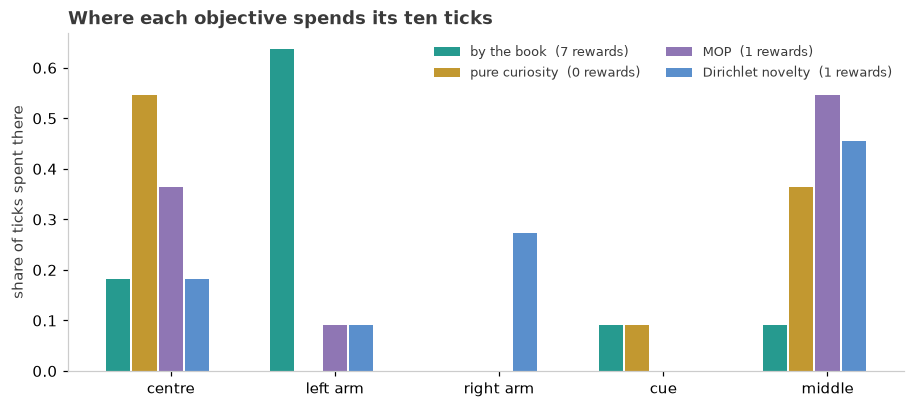

In [9]:
fig, ax = plt.subplots(figsize=(8.2, 3.6), constrained_layout=True)
names = list(visits)
width = 0.16
colors = [TEAL, AMBER, "#7B5EA7", "#3D7BC4", GREY]
for i, (name, counts) in enumerate(visits.items()):
    ax.bar(
        np.arange(5) + (i - 2) * width,
        counts / counts.sum(),
        width * 0.92,
        color=colors[i],
        alpha=0.85,
        label=f"{name}  ({rewards[name]} rewards)",
    )
ax.set_xticks(np.arange(5), LOC)
ax.set_ylabel("share of ticks spent there")
ax.set_title("Where each objective spends its ten ticks")
ax.legend(fontsize=8.5, ncols=2, frameon=False)
plt.show()

**What the five columns share.** One declared model; one planner; one term-tree contract. A
term is a bucket, an estimator computes a leaf into it, and which estimator runs is dispatched
by the variable's family — so `occupancy` reaches a closed form on this tabular System and a
neural estimator on a recurrent state-space one, under the same name and the same key.

**What they do not share.** Coherence. `utility + infogain` and `risk + ambiguity` are
packages that bound something; a tree carrying `occupancy` alone is a perfectly well-formed
objective that bounds nothing in particular. The library does not enforce that difference and
does not pretend to — coherence is documented, not enforced (`objective-terms.md`), and
`derived` answers the narrower question of whether a leaf's own arithmetic is a derivation.
Every leaf above is marked `exact` because every estimator here is a closed form over declared
tables; the same `occupancy` row over a neural transition is marked an estimate.